# Clasificación de solicitudes de tarjeta

## 1. Objetivo y datos

En un departamento de admisión de crédito, aprobar una operación problemática puede generar pérdidas y rechazar una solicitud adecuada puede suponer perder negocio. Para apoyar ese análisis interesa estudiar qué información aportan las características personales, laborales y financieras del solicitante y qué errores cometen los modelos al clasificar las solicitudes.

El proyecto utiliza dos archivos de **Credit card Details**, publicados en Kaggle: uno contiene los atributos y otro la decisión asociada a cada identificador. La fuente define `label` como **0 = aprobación registrada** y **1 = rechazo registrado**. Por tanto, se intentará clasificar esa decisión histórica, con el rechazo como clase positiva. No se dispone de un impago observado ni de las fechas necesarias para demostrar una predicción anterior a la concesión.

Se compararán regresión logística, árbol de decisión y Random Forest, considerando F1, recall, precisión, ROC-AUC y los errores de clasificación. La interpretación tendrá en cuenta tanto la detección de rechazos como las falsas alertas sobre aprobaciones y la posibilidad de explicar las predicciones.

El primer paso es conocer las dos tablas, comprobar su correspondencia y entender qué representan sus campos. Después se revisará la calidad y se definirá la evaluación, antes de explorar el entrenamiento, justificar los tratamientos y comparar modelos. El [README](../README.md) amplía el contexto y las reglas de comparación; la [memoria](../docs/Memoria-proyecto.md) recoge las decisiones y resultados del recorrido.

### Importaciones

In [1]:
# Datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación y evaluación
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold

# Modelos y referencias
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas y errores
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Utilidades
import json
import sys
from hashlib import sha256
from pathlib import Path
from IPython.display import display

# Reglas del proyecto
raiz_importacion = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(raiz_importacion) not in sys.path:
    sys.path.insert(0, str(raiz_importacion))
from src.preparacion import NUMERICAS, CATEGORICAS, BINARIAS, GRUPOS, representar_variables, agrupar_categorias, aplicar_reglas
from src.evaluacion import evaluar_candidatos

### Fuentes y carga

Cargamos los [dos archivos](../data/README.md): atributos y etiquetas. Comprobamos sus dimensiones antes de unirlos por `Ind_ID`.

In [2]:
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
DATOS = RAIZ / "data" / "raw"

clientes = pd.read_csv(DATOS / "Credit_card.csv", dtype={"Ind_ID": "string"})
etiquetas = pd.read_csv(DATOS / "Credit_card_label.csv", dtype={"Ind_ID": "string"})

display(pd.DataFrame(
    [clientes.shape, etiquetas.shape],
    index=["Atributos", "Etiquetas"],
    columns=["Registros", "Columnas"],
))

,Registros,Columnas
Atributos,1548,18
Etiquetas,1548,2


### Correspondencia entre tablas

Comprobamos que las claves sean únicas y estén informadas, y unimos las tablas sin perder ni multiplicar registros.

In [3]:
for nombre, tabla in {"Atributos": clientes, "Etiquetas": etiquetas}.items():
    if tabla["Ind_ID"].isna().any() or not tabla["Ind_ID"].is_unique:
        raise ValueError(f"{nombre}: revisar identificadores ausentes o repetidos.")

datos = clientes.merge(
    etiquetas, on="Ind_ID", how="outer", validate="one_to_one", indicator=True,
)
display(datos["_merge"].value_counts().rename_axis("Correspondencia").to_frame("Registros"))

if not datos["_merge"].eq("both").all():
    raise ValueError("Hay identificadores sin correspondencia entre las fuentes.")
datos = datos.drop(columns="_merge")

,Registros
Correspondencia,
both,1548
left_only,0
right_only,0


Las **1.548 claves coinciden en ambas tablas**, sin registros perdidos ni multiplicados. Mostramos la tabla unida con los atributos y `label`, omitiendo el identificador en esta vista.

In [4]:
display(datos.drop(columns="Ind_ID").head())

,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,label
0,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,-18772.0,365243,1,0,0,0,NaN,2,1
1,F,Y,Y,2,135000.0,Working,Secondary / secondary special,Married,House / apartment,-15761.0,-3173,1,0,0,0,Laborers,4,0
2,F,N,Y,0,247500.0,Commercial associate,Higher education,Separated,Rented apartment,-17016.0,-1347,1,0,0,0,Core staff,1,0
3,M,Y,Y,0,157500.0,Working,Secondary / secondary special,Married,House / apartment,-9927.0,-828,1,0,0,0,Drivers,2,0
4,F,N,Y,2,216000.0,State servant,Higher education,Married,House / apartment,-15444.0,-3112,1,0,0,1,NaN,4,0


### Primera lectura de los registros

Revisamos tipos, ausencias y número de valores distintos para localizar campos que requieran atención. El [diccionario](../docs/Diccionario-datos.md) aclara su significado.

In [5]:
display(pd.DataFrame({
    "Tipo leído": datos.dtypes.astype(str),
    "Ausentes": datos.isna().sum(),
    "Valores distintos": datos.nunique(),
}))

,Tipo leído,Ausentes,Valores distintos
Ind_ID,string,0,1548
GENDER,str,7,2
Car_Owner,str,0,2
Propert_Owner,str,0,2
CHILDREN,int64,0,6
Annual_income,float64,23,115
Type_Income,str,0,4
EDUCATION,str,0,5
Marital_status,str,0,5
Housing_type,str,0,6


`Mobile_phone` vale `1` en todas las observaciones: no distingue solicitudes y se puede excluir de los predictores.

`Type_Occupation` tiene **488 ausencias (31,52 %)**. Antes de imputarlas, conviene comprobar si responden a situaciones laborales diferentes.

### Etiqueta y entradas candidatas

Comprobamos los valores y el reparto de `label`. Separamos los atributos en `X`, la etiqueta en `y` y el identificador para control.

In [6]:
if datos["label"].isna().any() or not datos["label"].isin([0, 1]).all():
    raise ValueError("La etiqueta debe estar informada y contener únicamente 0 o 1.")

distribucion = datos["label"].value_counts().sort_index().to_frame("Registros")
distribucion["Porcentaje"] = (100 * distribucion["Registros"] / len(datos)).round(2)
distribucion.index = distribucion.index.map({0: "0 · Aprobación", 1: "1 · Rechazo"})
display(distribucion)

X = datos.drop(columns=["Ind_ID", "label"])
y = datos["label"]
identificadores = datos["Ind_ID"]

,Registros,Porcentaje
label,,
0 · Aprobación,1373,88.7
1 · Rechazo,175,11.3


### Lectura del bloque

Las tablas se emparejan en **1.548 registros**, con **17 atributos candidatos** y una etiqueta. Los **175 rechazos (11,30 %)** muestran que la exactitud por sí sola sería insuficiente para valorar la detección de la clase positiva.

Hay ausencias en género, ingreso, nacimiento y ocupación que requieren interpretación. La clave única no prueba que todos los registros correspondan a personas distintas. La falta de fechas y de una regla documentada de aprobación limita la interpretación a decisiones históricas.

Se conservan los valores de origen. La siguiente sección revisará la calidad y definirá las particiones antes de explorar relaciones o aprender tratamientos.

## 2. Calidad y evaluación

Revisamos códigos, coherencia y perfiles repetidos antes de fijar las muestras de evaluación. Conservamos los valores originales; los tratamientos que necesiten aprender de los datos se decidirán sobre entrenamiento.

### Códigos y coherencia básica

Comprobamos los dominios binarios, los recuentos y la coherencia entre los días de nacimiento y empleo. Las alertas señalan casos que requieren interpretación; no implican una corrección automática.

In [7]:
dominios = {
    "GENDER": ["F", "M"], "Car_Owner": ["Y", "N"], "Propert_Owner": ["Y", "N"],
    "Mobile_phone": [0, 1], "Work_Phone": [0, 1], "Phone": [0, 1], "EMAIL_ID": [0, 1],
}
alertas = {
    f"{campo}: fuera de dominio": (datos[campo].notna() & ~datos[campo].isin(valores)).sum()
    for campo, valores in dominios.items()
}
alertas.update({
    "Valores infinitos en campos numéricos": np.isinf(datos.select_dtypes("number")).sum().sum(),
    "Ingreso negativo": datos["Annual_income"].lt(0).sum(),
    "Hijos negativos o fraccionarios": (datos["CHILDREN"].lt(0) | datos["CHILDREN"].mod(1).ne(0)).sum(),
    "Familia menor que 1 o fraccionaria": (datos["Family_Members"].lt(1) | datos["Family_Members"].mod(1).ne(0)).sum(),
    "Nacimiento no negativo": datos["Birthday_count"].ge(0).sum(),
    "Inicio de empleo anterior al nacimiento": (
        datos["Employed_days"].le(0) & datos["Employed_days"].lt(datos["Birthday_count"])
    ).sum(),
    "Familia menor o igual al número de hijos": datos["Family_Members"].le(datos["CHILDREN"]).sum(),
})
display(pd.Series(alertas, name="Casos").to_frame())

,Casos
GENDER: fuera de dominio,0
Car_Owner: fuera de dominio,0
Propert_Owner: fuera de dominio,0
Mobile_phone: fuera de dominio,0
Work_Phone: fuera de dominio,0
Phone: fuera de dominio,0
EMAIL_ID: fuera de dominio,0
Valores infinitos en campos numéricos,0
Ingreso negativo,0
Hijos negativos o fraccionarios,0


Los dominios y rangos comprobados no presentan incidencias, salvo **dos registros con un hijo y un miembro de familia**. Se conservan: la definición disponible no permite resolver esa discrepancia. Los extremos plausibles se estudiarán después en entrenamiento.

### Empleo y ausencia de ocupación

Los días de empleo positivos necesitan una lectura distinta de la antigüedad. Comprobamos qué código aparece y su relación con el tipo de ingreso y las ausencias de ocupación.

In [8]:
empleo_positivo = datos["Employed_days"].gt(0)
display(datos.loc[empleo_positivo, "Employed_days"].value_counts().to_frame("Registros"))

contexto_empleo = datos.assign(
    Codigo_empleo=empleo_positivo.map({True: "Positivo", False: "No positivo"}),
    Sin_ocupacion=datos["Type_Occupation"].isna(),
).groupby(["Type_Income", "Codigo_empleo"], dropna=False).agg(
    Registros=("Ind_ID", "size"),
    Sin_ocupacion=("Sin_ocupacion", "sum"),
)
display(contexto_empleo)

,Registros
Employed_days,
365243,261


Registros  Sin_ocupacion
Type_Income          Codigo_empleo                          
Commercial associate No positivo          365             77
Pensioner            No positivo            8              3
                     Positivo             261            261
State servant        No positivo          116             18
Working              No positivo          798            129

El código **365243** aparece en **261 registros**, todos con ingreso `Pensioner` y ocupación ausente: no representa una antigüedad real. Quedan **227 ausencias de ocupación** entre los demás registros. Se conserva esta distinción para preparar las variables; no se interpreta toda ausencia como desempleo ni se imputa todavía.

### Perfiles repetidos y etiquetas distintas

Buscamos coincidencias en los 17 atributos, sin usar el identificador ni la etiqueta y considerando iguales las ausencias. Un perfil idéntico no demuestra que se trate de la misma persona.

In [9]:
# El orden de la fuente fija una base reproducible para las particiones.
datos_modelo = datos.set_index("Ind_ID").loc[clientes["Ind_ID"]].copy()
columnas_perfil = clientes.columns.drop("Ind_ID").tolist()
grupos_perfil = datos_modelo.groupby(columnas_perfil, dropna=False, sort=False).ngroup()
grupos_perfil = grupos_perfil.rename("grupo_perfil")

perfiles = datos_modelo.assign(grupo_perfil=grupos_perfil).groupby("grupo_perfil").agg(
    Registros=("label", "size"), Etiquetas=("label", "nunique"),
)
repetidos = perfiles["Registros"].gt(1)
discordantes = perfiles["Etiquetas"].gt(1)
display(pd.Series({
    "Perfiles distintos": len(perfiles),
    "Perfiles repetidos": repetidos.sum(),
    "Registros en perfiles repetidos": perfiles.loc[repetidos, "Registros"].sum(),
    "Perfiles con ambas etiquetas": discordantes.sum(),
    "Registros en perfiles con ambas etiquetas": perfiles.loc[discordantes, "Registros"].sum(),
}, name="Recuento").to_frame())

,Recuento
Perfiles distintos,1377
Perfiles repetidos,150
Registros en perfiles repetidos,321
Perfiles con ambas etiquetas,9
Registros en perfiles con ambas etiquetas,22


Hay **1.377 perfiles distintos**; **150** se repiten y reúnen **321 registros**. En **9 perfiles (22 registros)** aparecen aprobación y rechazo. Se conservan todas las filas y sus etiquetas, porque no hay evidencia para decidir qué registro sería erróneo.

Cada perfil permanecerá en una sola muestra de evaluación. Esto evita evaluar un perfil presente en entrenamiento, aunque no garantiza separar personas que tengan atributos diferentes.

### Campos para modelar

Excluimos `Mobile_phone`, que es constante. La clave y el grupo quedan como controles fuera de los predictores; los otros 16 atributos siguen siendo candidatos, con su pertinencia y preparación pendientes.

In [10]:
columnas_modelo = [campo for campo in columnas_perfil if campo != "Mobile_phone"]
X = datos_modelo[columnas_modelo].copy()
y = datos_modelo["label"].copy()
identificadores = datos_modelo.index

display(pd.Series({
    "Registros conservados": len(X),
    "Entradas candidatas": X.shape[1],
    "Atributos excluidos por constancia": len(columnas_perfil) - X.shape[1],
}, name="Recuento").to_frame())

,Recuento
Registros conservados,1548
Entradas candidatas,16
Atributos excluidos por constancia,1


### Reglas de evaluación

Reservamos aproximadamente un **20 % para el cierre** y usamos **cinco folds agrupados y estratificados** en desarrollo: cada perfil se valida una vez y permanece completo. Todos los candidatos compartirán esas particiones.

La comparación principal será el **F1 medio de la clase rechazo**, con umbral inicial **0,5**; se acompañará de dispersión entre folds, recall, precisión, ROC-AUC y matriz de confusión. Las referencias serán predecir siempre la clase mayoritaria y predecir siempre rechazo.

Dentro de **0,01 de F1** del mejor resultado se priorizará la familia más sencilla: logística, árbol y bosque, en ese orden; dentro de una familia, menor dispersión y después mayor F1. Es una tolerancia práctica, no un umbral de utilidad bancaria ni una prueba de equivalencia. Cualquier ajuste posterior de umbral se hará solo en desarrollo.

### Reserva y validación por perfiles

Fijamos las semillas y el orden de entrada con la [configuración de evaluación](../evaluacion/configuracion.json). La primera exploración utilizará solo el entrenamiento del primer fold; los tratamientos se volverán a ajustar dentro de cada fold al comparar modelos.

In [11]:
EVALUACION = RAIZ / "evaluacion"
configuracion = json.loads((EVALUACION / "configuracion.json").read_text(encoding="utf-8"))
for archivo, huella in configuracion["sha256_fuentes"].items():
    if sha256((DATOS / archivo).read_bytes()).hexdigest() != huella:
        raise ValueError("Los datos han cambiado: revisar la configuración antes de repartir.")

reserva = StratifiedGroupKFold(
    n_splits=configuracion["bloques_reserva"], shuffle=True,
    random_state=configuracion["semilla_test"],
)
i_dev, i_test = next(reserva.split(X, y, groups=grupos_perfil))
X_dev, y_dev, grupos_dev = X.iloc[i_dev].copy(), y.iloc[i_dev].copy(), grupos_perfil.iloc[i_dev].copy()
X_test, y_test, grupos_test = X.iloc[i_test].copy(), y.iloc[i_test].copy(), grupos_perfil.iloc[i_test].copy()

cv = StratifiedGroupKFold(
    n_splits=configuracion["folds_desarrollo"], shuffle=True,
    random_state=configuracion["semilla_cv"],
)
particiones = list(cv.split(X_dev, y_dev, groups=grupos_dev))
i_train, i_valid = particiones[0]
X_train, y_train = X_dev.iloc[i_train].copy(), y_dev.iloc[i_train].copy()
X_valid, y_valid = X_dev.iloc[i_valid].copy(), y_dev.iloc[i_valid].copy()

In [12]:
assert X.index.equals(y.index) and X.index.equals(grupos_perfil.index)
assert len(np.unique(np.concatenate([i_dev, i_test]))) == len(X)
assert set(grupos_dev).isdisjoint(grupos_test)
assert y_dev.nunique() == y_test.nunique() == 2

resumen_folds = []
for fold, (tr, va) in enumerate(particiones, start=1):
    assert not np.intersect1d(tr, va).size
    assert len(tr) + len(va) == len(X_dev)
    assert set(grupos_dev.iloc[tr]).isdisjoint(grupos_dev.iloc[va])
    assert y_dev.iloc[tr].nunique() == y_dev.iloc[va].nunique() == 2
    resumen_folds.append({
        "Fold": fold, "Entrenamiento": len(tr), "Rechazos entrenamiento": int(y_dev.iloc[tr].sum()),
        "Validación": len(va), "Rechazos validación": int(y_dev.iloc[va].sum()),
    })
assert np.array_equal(np.sort(np.concatenate([va for _, va in particiones])), np.arange(len(X_dev)))

resumen_muestras = pd.DataFrame([
    {"Muestra": nombre, "Registros": len(etiqueta), "Perfiles": grupo.nunique(),
     "Rechazos": int(etiqueta.sum()), "Rechazos (%)": round(100 * etiqueta.mean(), 2)}
    for nombre, etiqueta, grupo in [("Desarrollo", y_dev, grupos_dev), ("Test", y_test, grupos_test)]
]).set_index("Muestra")
resumen_folds = pd.DataFrame(resumen_folds).set_index("Fold")
display(resumen_muestras, resumen_folds)

,Registros,Perfiles,Rechazos,Rechazos (%)
Muestra,,,,
Desarrollo,1238,1102,140,11.31
Test,310,275,35,11.29


,Entrenamiento,Rechazos entrenamiento,Validación,Rechazos validación
Fold,,,,
1,990,112,248,28
2,990,112,248,28
3,991,112,247,28
4,990,112,248,28
5,991,112,247,28


Quedan **1.238 registros en desarrollo y 310 en test**, con **140 y 35 rechazos**, respectivamente. Cada validación contiene **28 rechazos** y no comparte perfiles con su entrenamiento. La primera exploración dispone de **990 registros de entrenamiento**.

El conjunto público ya ha sido examinado: esta reserva permite mantener separado el cierre durante el recorrido, pero sus resultados serán una **evaluación interna**, no una prueba nueva e independiente. Además, el reducido número de rechazos aconseja interpretar con cautela diferencias pequeñas.

### Conservación de las particiones

Guardamos la asignación por identificador y fold para reutilizarla sin cambiar el reparto. El archivo individual queda excluido de Git; la configuración y los resúmenes agregados sí se pueden consultar en el repositorio.

In [13]:
registro_particiones = grupos_perfil.to_frame().assign(uso="test", orden_en_uso=0, fold_validacion=0)
registro_particiones.loc[X_dev.index, "uso"] = "desarrollo"
registro_particiones.loc[X_dev.index, "orden_en_uso"] = np.arange(len(X_dev))
registro_particiones.loc[X_test.index, "orden_en_uso"] = np.arange(len(X_test))
for fold, (_, va) in enumerate(particiones, start=1):
    registro_particiones.loc[X_dev.index[va], "fold_validacion"] = fold

ruta_particiones = EVALUACION / "particiones.csv"
if ruta_particiones.exists():
    guardadas = pd.read_csv(ruta_particiones, dtype={"Ind_ID": "string"}).set_index("Ind_ID")
    pd.testing.assert_frame_equal(guardadas.sort_index(), registro_particiones.sort_index())
else:
    registro_particiones.to_csv(ruta_particiones)
resumen_muestras.to_csv(EVALUACION / "resumen_muestras.csv")
resumen_folds.to_csv(EVALUACION / "resumen_folds.csv")
print("Particiones conservadas y comprobadas; resúmenes de muestras y folds guardados.")

Particiones conservadas y comprobadas; resúmenes de muestras y folds guardados.


### Lectura del bloque

Se conservan los **1.548 registros** y se retira únicamente el móvil constante de los predictores. Las alertas familiares, las ausencias y el código de empleo quedan identificados; no se han imputado valores, agrupado categorías ni aprendido transformaciones.

Los perfiles completos quedan separados entre desarrollo y test y entre entrenamiento y validación. Están fijados el criterio de comparación y las referencias, pero todavía no hay modelos entrenados ni métricas predictivas. El siguiente paso será explorar el entrenamiento, justificar agrupaciones con sentido y decidir la preparación de las variables.

## 3. Exploración y preparación

Estudiamos los **990 registros del entrenamiento del primer fold**, con 112 rechazos. A partir de sus distribuciones y categorías fijamos una preparación inicial; su utilidad predictiva se comprobará al comparar modelos.

### Variables y representaciones para explorar

Convertimos los días relativos en años aproximados. El código positivo de empleo se representa por separado y deja la duración sin interpretar; los indicadores de contacto siguen siendo categorías binarias. Las reglas reutilizables están en [preparacion.py](../src/preparacion.py).

In [14]:
vista = representar_variables(X_train)
cantidades = vista[NUMERICAS]
nombres = {
    "Annual_income": "Ingreso anual", "CHILDREN": "Hijos", "Family_Members": "Miembros de familia",
    "Edad_anios": "Edad (años)", "Antiguedad_anios": "Antigüedad (años)",
}
resumen_numerico = cantidades.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
resumen_numerico["ausentes"] = cantidades.isna().sum()
display(resumen_numerico.rename(index=nombres).round(2))

,count,mean,std,min,25%,50%,75%,99%,max,ausentes
Ingreso anual,972.0,193982.87,123570.18,36000.0,121050.00,162000.00,225000.00,599220.00,1575000.00,18
Hijos,990.0,0.43,0.82,0.0,0.00,0.00,1.00,3.00,14.00,0
Miembros de familia,990.0,2.18,0.98,1.0,2.00,2.00,3.00,5.00,15.00,0
Edad (años),974.0,43.64,11.33,21.1,33.97,42.40,52.83,66.52,67.52,16
Antigüedad (años),831.0,7.03,6.02,0.2,2.53,5.35,9.65,26.88,35.24,159


La edad y la antigüedad se expresan respecto a la referencia del archivo, no al día de ejecución. Las **159 duraciones sin interpretar** corresponden al código especial de empleo; no entran como antigüedades reales en los gráficos.

### Distribuciones, extremos y relaciones numéricas

Combinamos histogramas y frecuencias según el tipo de cantidad. El boxplot del ingreso ayuda a localizar extremos, que se revisarán junto a su contexto antes de decidir un tratamiento.

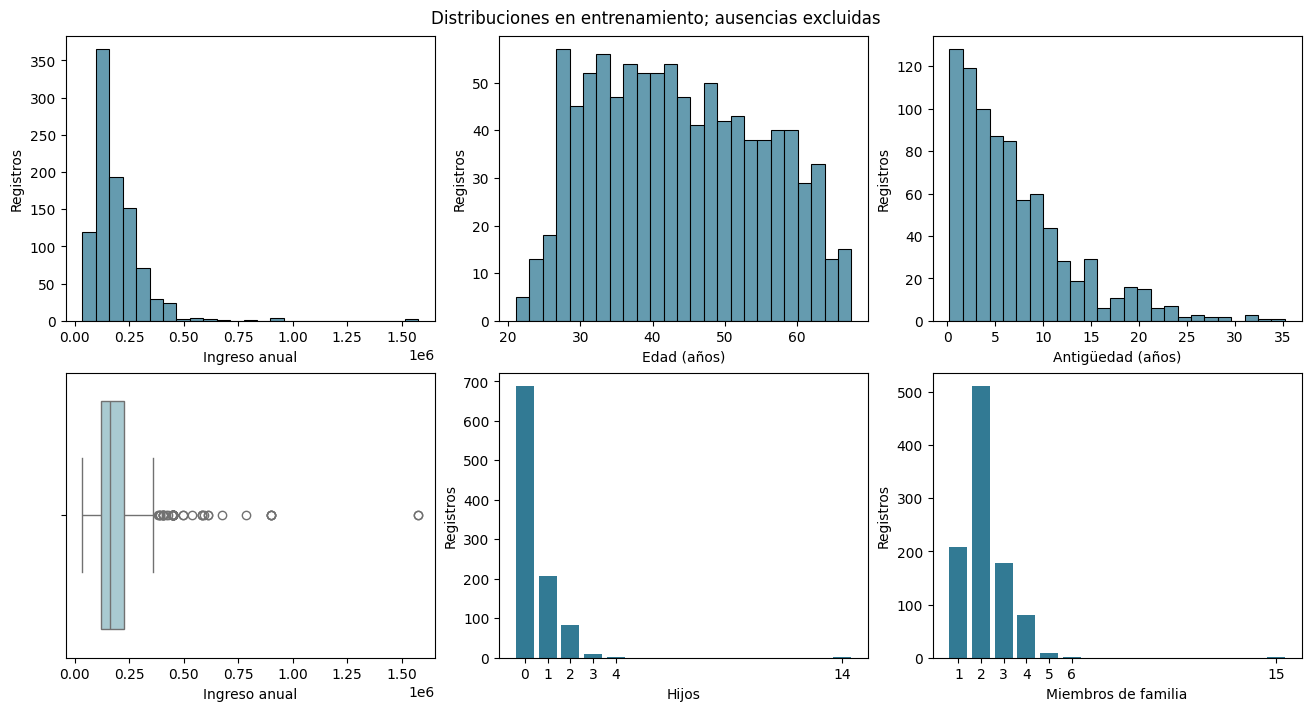

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for ax, campo in zip(axes[0], ["Annual_income", "Edad_anios", "Antiguedad_anios"]):
    sns.histplot(cantidades[campo].dropna(), bins=25, ax=ax, color="#327a94")
    ax.set(xlabel=nombres[campo], ylabel="Registros")
sns.boxplot(x=cantidades["Annual_income"], ax=axes[1, 0], color="#a2ced8")
axes[1, 0].set(xlabel="Ingreso anual")
for ax, campo in zip(axes[1, 1:], ["CHILDREN", "Family_Members"]):
    frecuencia = cantidades[campo].value_counts().sort_index()
    ax.bar(frecuencia.index, frecuencia.values, color="#327a94")
    ax.set(xlabel=nombres[campo], ylabel="Registros", xticks=frecuencia.index)
fig.suptitle("Distribuciones en entrenamiento; ausencias excluidas")
plt.show()

In [16]:
q1, q3 = X_train["Annual_income"].quantile([0.25, 0.75])
limite_iqr = q3 + 1.5 * (q3 - q1)
p99_ingreso = X_train["Annual_income"].quantile(0.99)
display(pd.Series({
    "Límite exploratorio IQR": limite_iqr,
    "Registros por encima del IQR": X_train["Annual_income"].gt(limite_iqr).sum(),
    "Percentil 99 del ingreso (diagnóstico)": p99_ingreso,
    "Registros que limitaría el P99": X_train["Annual_income"].gt(p99_ingreso).sum(),
}, name="Valor").to_frame())
casos_extremos = X_train.nlargest(3, "Annual_income").index.union(
    X_train.nlargest(1, "CHILDREN").index, sort=False,
)
display(X_train.loc[casos_extremos, [
    "Annual_income", "Type_Income", "Type_Occupation", "CHILDREN", "Family_Members",
]].reset_index(drop=True))

,Valor
Límite exploratorio IQR,380925.0
Registros por encima del IQR,50.0
Percentil 99 del ingreso (diagnóstico),599220.0
Registros que limitaría el P99,10.0


,Annual_income,Type_Income,Type_Occupation,CHILDREN,Family_Members
0,1575000.0,Commercial associate,Managers,1,2
1,1575000.0,Commercial associate,Managers,1,2
2,900000.0,Working,Laborers,1,3
3,225000.0,Working,Drivers,14,15


Hay **50 ingresos por encima de 380.925**, incluidos dos de **1.575.000**, y un registro con **14 hijos y 15 miembros de familia**. Su rareza no confirma un error: mantenemos las filas y sus valores como referencia inicial.

Un límite en el **P99 (599.220)** afectaría a **10 ingresos**, no solo a los dos máximos. Lo reservamos para una comparación posterior, aprendiendo el percentil dentro de cada entrenamiento. No aplicamos ahora recortes ni topes arbitrarios a hijos o familia.

Comparamos ahora las cantidades con la etiqueta y entre sí. Para visualizar el ingreso por clase usamos un eje logarítmico; esto no transforma la entrada del modelo.

,Ingreso anual,Edad (años),Antigüedad (años)
label,,,
Aprobación,157500.0,42.28,5.74
Rechazo,180000.0,44.36,3.18


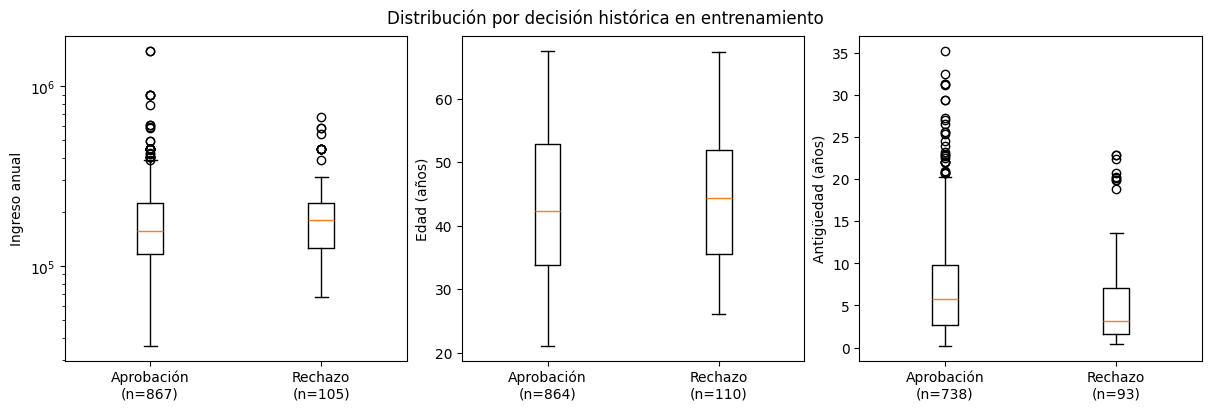

In [17]:
campos_clase = ["Annual_income", "Edad_anios", "Antiguedad_anios"]
display(cantidades[campos_clase].groupby(y_train).median().rename(
    index={0: "Aprobación", 1: "Rechazo"}, columns=nombres,
).round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, campo in zip(axes, campos_clase):
    muestras = [cantidades.loc[y_train.eq(clase), campo].dropna() for clase in [0, 1]]
    etiquetas = [f"{clase}\n(n={len(muestra)})"
                 for clase, muestra in zip(["Aprobación", "Rechazo"], muestras)]
    ax.boxplot(muestras, tick_labels=etiquetas)
    ax.set(ylabel=nombres[campo])
    if campo == "Annual_income":
        ax.set_yscale("log")
fig.suptitle("Distribución por decisión histórica en entrenamiento")
plt.show()

La línea central representa la **mediana**: la antigüedad es **5,74 años en aprobaciones y 3,18 en rechazos**, con solapamiento. Ingreso y edad también se solapan; eso no descarta una aportación conjunta al modelo ni justifica asignar pesos manualmente.

Cada caja abarca del percentil 25 al 75 de su grupo; más registros no implican una caja más alta. El `n` indica los valores disponibles en cada gráfico, excluidas las ausencias y las duraciones sin interpretar.

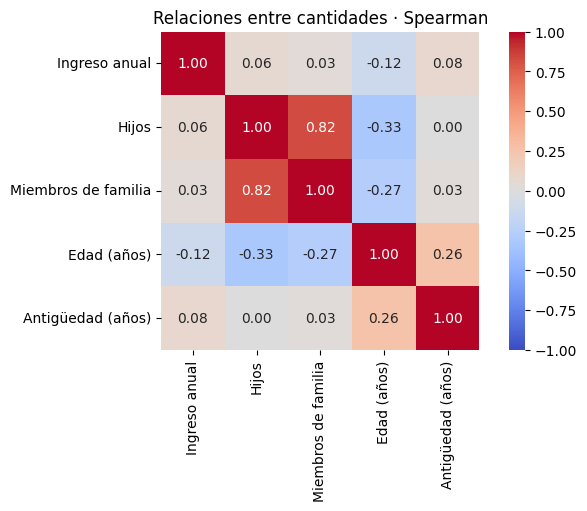

In [18]:
correlaciones = cantidades.rename(columns=nombres).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
sns.heatmap(correlaciones, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="coolwarm", square=True, ax=ax)
ax.set_title("Relaciones entre cantidades · Spearman")
plt.show()

Hijos y miembros de familia comparten información: **Spearman = 0,823**. La correlación no implica que sean intercambiables. Comprobamos qué diferencia queda entre ambos recuentos antes de proponer una reducción de entradas.

### Relación entre familia, hijos y estado civil

Calculamos `Family_Members − CHILDREN` y lo cruzamos con el estado civil, el ingreso y el rechazo. La diferencia describe los recuentos registrados; no acredita cuántos adultos conviven ni cuántas personas aportan ingresos.

In [19]:
composicion = X_train[["Family_Members", "CHILDREN", "Marital_status", "Annual_income"]].assign(
    Diferencia_familia_hijos=lambda tabla: tabla["Family_Members"] - tabla["CHILDREN"],
    label=y_train,
)
cruce_familiar = pd.crosstab(composicion["Marital_status"], composicion["Diferencia_familia_hijos"])
resumen_familiar = composicion.groupby("Diferencia_familia_hijos").agg(
    Registros=("label", "size"),
    Rechazos=("label", "sum"),
    Ingresos_informados=("Annual_income", "count"),
    Ingreso_mediano=("Annual_income", "median"),
)
resumen_familiar.insert(2, "Rechazo (%)", 100 * resumen_familiar["Rechazos"] / resumen_familiar["Registros"])
display(cruce_familiar, resumen_familiar.round(2))

Diferencia_familia_hijos,1,2
Marital_status,,
Civil marriage,0,68
Married,0,667
Separated,55,0
Single / not married,147,10
Widow,43,0


,Registros,Rechazos,Rechazo (%),Ingresos_informados,Ingreso_mediano
Diferencia_familia_hijos,,,,,
1,245,29,11.84,237,175500.0
2,745,83,11.14,735,157500.0


La diferencia vale **1 en 245 registros y 2 en 745**; está muy ligada al estado civil. El rechazo es **11,84 % y 11,14 %**, respectivamente, y el ingreso mediano **175.500 y 157.500**. Estos datos no respaldan que el primer grupo tenga menor ingreso registrado; tampoco permiten inferir ingresos totales del hogar ni un efecto del divorcio.

Conservamos ambas cantidades como referencia y no añadimos la diferencia al modelo. Para comprobar si simplificar ayuda, compararemos después una variante **sin `CHILDREN`**, manteniendo `Family_Members` y `Marital_status`; aún no hay evidencia de mejora predictiva.

### Categorías y agrupaciones con significado

Revisamos frecuencias y rechazo registrado, incluidos los indicadores binarios. Los gráficos se centran en las tres variables que agruparemos; el [resumen completo](../reports/resumen_categorias_entrenamiento.csv) conserva todos los niveles y sus recuentos.

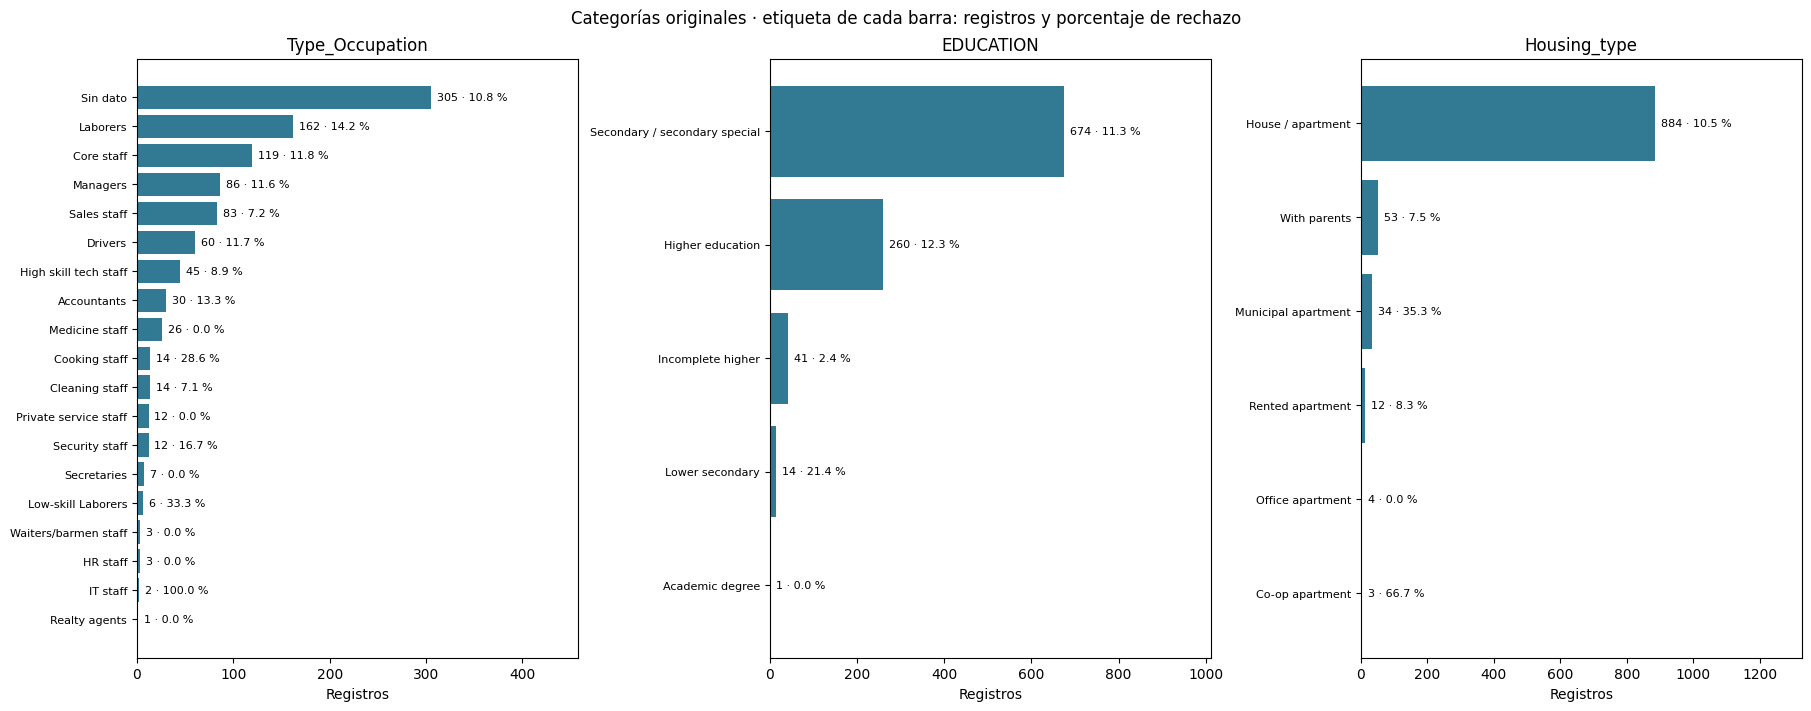

In [20]:
resumen_categorias = pd.concat({
    campo: y_train.groupby(X_train[campo], dropna=False).agg(Registros="size", Rechazos="sum")
    for campo in CATEGORICAS + ["Work_Phone", "Phone", "EMAIL_ID"]
}, names=["Variable", "Nivel"])
resumen_categorias["Rechazo (%)"] = 100 * resumen_categorias["Rechazos"] / resumen_categorias["Registros"]
REPORTS = RAIZ / "reports"
REPORTS.mkdir(exist_ok=True)
resumen_categorias.to_csv(REPORTS / "resumen_categorias_entrenamiento.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")
for ax, campo in zip(axes, GRUPOS):
    tabla = resumen_categorias.loc[campo].sort_values("Registros")
    niveles = tabla.index.to_series().fillna("Sin dato").astype(str)
    ax.barh(niveles, tabla["Registros"], color="#327a94")
    for j, (_, fila) in enumerate(tabla.iterrows()):
        ax.text(fila["Registros"] + tabla["Registros"].max() * 0.02, j,
                f'{int(fila["Registros"])} · {fila["Rechazo (%)"]:.1f} %', va="center", fontsize=8)
    ax.set(xlabel="Registros", title=campo, xlim=(0, tabla["Registros"].max() * 1.5))
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Categorías originales · etiqueta de cada barra: registros y porcentaje de rechazo")
plt.show()

`IT staff` tiene **dos registros y dos rechazos**; esa tasa no permite concluir que toda la ocupación tenga el mismo comportamiento. Agruparemos por actividad y significado, sin utilizar las tasas para elegir qué categorías juntar.

In [21]:
correspondencias = pd.DataFrame([
    {"Variable": campo, "Grupo": grupo, "Categorías originales": ", ".join(niveles)}
    for campo, grupos in GRUPOS.items() for grupo, niveles in grupos.items()
])
with pd.option_context("display.max_colwidth", None):
    display(correspondencias)
correspondencias.to_csv(REPORTS / "agrupaciones_categoricas.csv", index=False)

,Variable,Grupo,Categorías originales
0,Type_Occupation,Administracion_y_gestion,"Accountants, HR staff, Managers, Secretaries"
1,Type_Occupation,Tecnicas_y_profesionales,"High skill tech staff, IT staff, Medicine staff"
2,Type_Occupation,Produccion_y_transporte,"Laborers, Low-skill Laborers, Drivers"
3,Type_Occupation,Ventas,"Sales staff, Realty agents"
4,Type_Occupation,Servicios_de_apoyo,"Cleaning staff, Cooking staff, Private service staff, Security staff, Waiters/barmen staff"
5,Type_Occupation,Personal_general,Core staff
6,EDUCATION,Superior_completa,"Academic degree, Higher education"
7,EDUCATION,Superior_incompleta,Incomplete higher
8,EDUCATION,Secundaria,"Lower secondary, Secondary / secondary special"
9,Housing_type,Casa_o_apartamento,House / apartment


En ocupación se usan familias amplias de actividad; `Core staff` queda separado por su significado impreciso. Educación distingue secundaria, superior incompleta y superior completa. Vivienda reúne las modalidades institucionales o colectivas, sin llamar alquiler a todas ellas ni atribuir propiedad a «casa o apartamento». La [justificación de las agrupaciones](../docs/Agrupaciones-categoricas.md) detalla los límites de esta simplificación.

In [22]:
vista_agrupada = agrupar_categorias(vista)
comparacion_niveles = pd.DataFrame({
    "Niveles originales (sin ausencias)": X_train[list(GRUPOS)].nunique(),
    "Grupos resultantes (sin ausencias)": [
        vista_agrupada.loc[X_train[campo].notna(), campo].nunique() for campo in GRUPOS
    ],
})
display(comparacion_niveles)
resumen_agrupado = pd.concat({
    campo: y_train.groupby(vista_agrupada[campo].fillna("__AUSENTE__")).agg(Registros="size", Rechazos="sum")
    for campo in GRUPOS
}, names=["Variable", "Grupo"])
resumen_agrupado["Rechazo (%)"] = 100 * resumen_agrupado["Rechazos"] / resumen_agrupado["Registros"]
display(resumen_agrupado.round(2))
resumen_agrupado.to_csv(REPORTS / "resumen_agrupaciones_entrenamiento.csv")

,Niveles originales (sin ausencias),Grupos resultantes (sin ausencias)
Type_Occupation,18,6
EDUCATION,5,3
Housing_type,6,4


Registros  Rechazos  Rechazo (%)
Variable        Grupo                                                      
Type_Occupation Administracion_y_gestion         126        14        11.11
                Personal_general                 119        14        11.76
                Produccion_y_transporte          228        32        14.04
                Servicios_de_apoyo                55         7        12.73
                Tecnicas_y_profesionales          73         6         8.22
                Ventas                            84         6         7.14
                __AUSENTE__                      305        33        10.82
EDUCATION       Secundaria                       688        79        11.48
                Superior_completa                261        32        12.26
                Superior_incompleta               41         1         2.44
Housing_type    Alquiler_declarado                12         1         8.33
                Casa_o_apartamento               884        93        10.52
                Con_familiares                    53         4         7.55
                Institucional_o_colectiva         41        14        34.15

Ocupación pasa de **18 niveles informados a 6 grupos**, educación de **5 a 3** y vivienda de **6 a 4**. Los grupos de ocupación tienen entre **55 y 228 registros**, además de la ausencia explícita. El alquiler declarado conserva 12 casos: se mantiene separado por significado, sin forzar un mínimo común. La mejora predictiva de estas agrupaciones sigue pendiente de validación.

### Ausencias y decisiones de tratamiento

Comparamos los casos con y sin dato para justificar su representación. Los porcentajes se acompañan del tamaño de cada grupo; una diferencia con pocos registros solo plantea una hipótesis.

In [23]:
resumen_ausencias = pd.concat({
    campo: y_train.groupby(X_train[campo].isna().map({False: "Informado", True: "Ausente"})).agg(
        Registros="size", Rechazos="sum",
    )
    for campo in X_train.columns[X_train.isna().any()]
}, names=["Variable", "Estado"])
resumen_ausencias["Rechazo (%)"] = 100 * resumen_ausencias["Rechazos"] / resumen_ausencias["Registros"]
display(resumen_ausencias.round(2))

Registros  Rechazos  Rechazo (%)
Variable        Estado                                     
GENDER          Ausente            2         1        50.00
                Informado        988       111        11.23
Annual_income   Ausente           18         7        38.89
                Informado        972       105        10.80
Birthday_count  Ausente           16         2        12.50
                Informado        974       110        11.29
Type_Occupation Ausente          305        33        10.82
                Informado        685        79        11.53

Falta ingreso en **18 registros**, con **7 rechazos (38,89 %)**. Incluimos un indicador de ausencia como hipótesis inicial, cuya aportación deberá contrastarse. De las **305 ocupaciones ausentes**, 159 acompañan al código positivo y 146 no; el indicador de empleo mantiene distinguibles ambos contextos.

| Entrada | Preparación inicial y motivo |
|---|---|
| Ingreso y edad ausentes | Mediana aprendida en entrenamiento; el ingreso asimétrico aconseja una referencia resistente a sus extremos. No se supone que un ingreso desconocido sea bajo o cero. |
| Código especial de empleo | Indicador propio y duración de soporte igual a cero; no representa una antigüedad observada ni experiencia laboral total. |
| Categorías ausentes | `__AUSENTE__`, sin atribuir género u ocupación desconocidos a la categoría mayoritaria. |
| Ingreso ausente | Indicador calculado antes de imputar. |
| Extremos y familia | Conservar filas y ambas cantidades en la referencia inicial. Contrastar después, por separado, el límite P99 del ingreso y la exclusión de `CHILDREN`. |

### Preparación reutilizable

Unimos las reglas fijas con imputación, codificación y escalado. Ajustamos aquí una vista de diagnóstico usando solo entrenamiento; al comparar modelos, el pipeline completo se volverá a ajustar en cada fold. El escalado se utilizará para logística y se podrá desactivar para los árboles.

In [24]:
numericas = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])
columnas = ColumnTransformer([
    ("num", numericas, NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ("bin", "passthrough", BINARIAS),
], verbose_feature_names_out=False).set_output(transform="pandas")
preparacion = Pipeline([
    ("representar", FunctionTransformer(representar_variables)),
    ("reglas", FunctionTransformer(aplicar_reglas)),
    ("columnas", columnas),
])
Z_train = preparacion.fit_transform(X_train)
assert Z_train.index.equals(X_train.index) and np.isfinite(Z_train.to_numpy()).all()
print(f"Preparación ajustada: {Z_train.shape[0]} filas y {Z_train.shape[1]} columnas numéricas.")

Preparación ajustada: 990 filas y 40 columnas numéricas.


### Comprobación del resultado y cierre

Revisamos qué valores aprendió el imputador y dónde se aplicaron, antes del escalado. Los ceros de duración asociados al código especial son una regla fija diferenciada por su indicador, no medianas aprendidas.

In [25]:
vista_reglas = aplicar_reglas(vista)
imputador = preparacion.named_steps["columnas"].named_transformers_["num"].named_steps["imputar"]
numericas_imputadas = pd.DataFrame(
    imputador.transform(vista_reglas[NUMERICAS]), index=X_train.index, columns=NUMERICAS,
)
resumen_imputacion = pd.DataFrame({
    "Ausencias antes del imputador": vista_reglas[NUMERICAS].isna().sum(),
    "Mediana aprendida": imputador.statistics_,
    "Ausencias después": numericas_imputadas.isna().sum(),
})
display(resumen_imputacion.round(3))
resumen_imputacion.to_csv(REPORTS / "imputacion_entrenamiento.csv")
vista_preparada = vista_reglas.copy()
vista_preparada[NUMERICAS] = numericas_imputadas
display(vista_preparada[["Edad_anios", "Antiguedad_anios", "Codigo_empleo_positivo",
                     "Ingreso_ausente", "Type_Occupation", "EDUCATION", "Housing_type"]].head().reset_index(drop=True))

,Ausencias antes del imputador,Mediana aprendida,Ausencias después
Annual_income,18,162000.000,0
CHILDREN,0,0.000,0
Family_Members,0,2.000,0
Edad_anios,16,42.401,0
Antiguedad_anios,0,4.261,0


,Edad_anios,Antiguedad_anios,Codigo_empleo_positivo,Ingreso_ausente,Type_Occupation,EDUCATION,Housing_type
0,37.117043,1.604381,0,0,__AUSENTE__,Superior_completa,Casa_o_apartamento
1,42.401095,1.604381,0,0,__AUSENTE__,Superior_completa,Casa_o_apartamento
2,37.117043,1.604381,0,1,__AUSENTE__,Superior_completa,Casa_o_apartamento
3,37.117043,1.604381,0,0,__AUSENTE__,Superior_completa,Casa_o_apartamento
4,37.117043,1.604381,0,0,__AUSENTE__,Superior_completa,Casa_o_apartamento


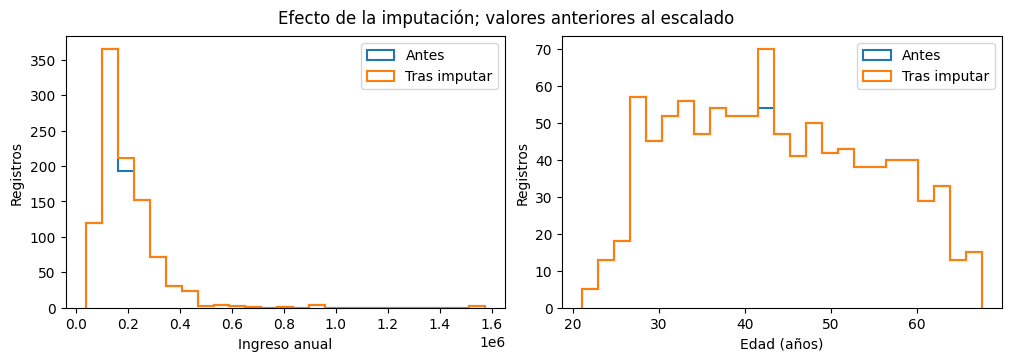

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, campo in zip(axes, ["Annual_income", "Edad_anios"]):
    bins = np.histogram_bin_edges(numericas_imputadas[campo], bins=25)
    ax.hist(vista_reglas[campo].dropna(), bins=bins, histtype="step", linewidth=1.5, label="Antes")
    ax.hist(numericas_imputadas[campo], bins=bins, histtype="step", linewidth=1.5, label="Tras imputar")
    ax.set(xlabel=nombres[campo], ylabel="Registros")
    ax.legend()
fig.suptitle("Efecto de la imputación; valores anteriores al escalado")
plt.show()

Se imputan **18 ingresos y 16 edades**; los valores informados permanecen intactos antes de escalar. La preparación produce **40 columnas** y conserva las 990 filas. Una categoría futura no reconocida se codificará con ceros en su bloque; comprobamos ese comportamiento con un ejemplo sintético, sin consultar validación ni test.

In [27]:
prueba = X_train.iloc[[0]].copy()
prueba["Type_Occupation"] = "Ocupacion_nueva"
prueba["Annual_income"] = np.nan
estadisticas_antes = imputador.statistics_.copy()
Z_prueba = preparacion.transform(prueba)

assert Z_prueba.columns.equals(Z_train.columns) and np.isfinite(Z_prueba.to_numpy()).all()
assert Z_prueba.filter(like="Type_Occupation_").eq(0).all().all()
assert Z_prueba["Ingreso_ausente"].eq(1).all()
np.testing.assert_array_equal(imputador.statistics_, estadisticas_antes)
print("Ejemplo sintético aceptado: categoría nueva, ingreso ausente y estadísticas sin reajuste.")

Ejemplo sintético aceptado: categoría nueva, ingreso ausente y estadísticas sin reajuste.


La preparación inicial queda definida: años e indicadores interpretables, agrupaciones semánticas, ausencias explícitas y medianas aprendidas en entrenamiento. Se conservan las 990 filas, los extremos y ambas cantidades familiares. La diferencia familia–hijos se ha explorado, pero no se añade al pipeline.

El siguiente bloque comparará referencias y modelos con esta preparación, reajustada en cada fold. Para las mejoras quedan dos contrastes numéricos concretos: limitar el ingreso al P99 y excluir `CHILDREN`, por separado frente a la misma referencia. No se ha probado aún su efecto predictivo ni el de las agrupaciones.

## 4. Comparación inicial de modelos

Comparamos dos referencias y tres modelos en los **1.238 registros de desarrollo**, con los cinco folds ya fijados. La clase positiva es el rechazo registrado y el umbral inicial es **0,5**; el criterio principal será el F1 medio entre folds.

Mantenemos la preparación revisada, los extremos y ambas cantidades familiares. El test queda reservado; esta comparación sigue siendo una evaluación interna sobre datos públicos ya examinados.

### Referencias y modelos candidatos

Las referencias muestran qué se consigue sin aprender relaciones entre atributos. Los tres modelos usan una configuración inicial, sin ponderación de clases; los valores elegidos no se consideran óptimos.

| Candidato | Configuración inicial | Propósito |
|---|---|---|
| Mayoritaria | Clase más frecuente de cada entrenamiento | Contextualizar la accuracy. |
| Siempre rechazo | Predecir siempre 1 | Contextualizar el recall. |
| Logística | L2, C=1; escalado numérico | Primera relación conjunta sencilla. |
| Árbol | Profundidad máxima 5; mínimo 5 registros por hoja | Reglas e interacciones con crecimiento limitado. |
| Random Forest | 200 árboles; mínimo 2 por hoja; sin límite fijo de profundidad | Explorar mayor capacidad sin restringirla a árboles poco profundos. |

In [28]:
estimadores = {
    "Logística": LogisticRegression(C=1.0, l1_ratio=0.0, solver="lbfgs", max_iter=2000),
    "Árbol": DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=None, min_samples_leaf=2,
        max_features="sqrt", random_state=42, n_jobs=-1,
    ),
}
preparacion_arboles = clone(preparacion).set_params(columnas__num__escalar="passthrough")
candidatos = {
    "Mayoritaria": DummyClassifier(strategy="prior"),
    "Siempre rechazo": DummyClassifier(strategy="constant", constant=1),
}
for nombre, estimador in estimadores.items():
    base = preparacion if nombre == "Logística" else preparacion_arboles
    candidatos[nombre] = Pipeline([
        ("preparar", clone(base)),
        ("modelo", estimador),
    ])

### Entrenamiento y validación comunes

La [rutina de evaluación](../src/evaluacion.py) clona cada candidato, ajusta su pipeline solo con el entrenamiento del fold y predice su validación. Las referencias no necesitan preparar atributos. Se conservan también el F1 de entrenamiento y las predicciones de validación para interpretar los errores.

Cada registro se valida una vez. No se reutiliza `Z_train` como entrada de la comparación ni se ocultan avisos del entrenamiento.

In [29]:
UMBRAL = configuracion["umbral_inicial"]
por_fold, predicciones_cv = evaluar_candidatos(candidatos, X_dev, y_dev, particiones, UMBRAL)
cobertura = predicciones_cv.groupby("Modelo", sort=False).agg(
    Registros=("Ind_ID", "size"), Identificadores=("Ind_ID", "nunique"), Folds=("Fold", "nunique"),
)
assert cobertura["Registros"].eq(len(X_dev)).all()
assert cobertura["Identificadores"].eq(len(X_dev)).all() and cobertura["Folds"].eq(5).all()
print(f"{len(por_fold)} ajustes: {len(candidatos)} candidatos × {len(particiones)} folds; "
      f"{len(X_dev)} predicciones de validación por candidato.")

25 ajustes: 5 candidatos × 5 folds; 1238 predicciones de validación por candidato.


### Resultados y estabilidad

Promediamos cada métrica dando el mismo peso a los cinco folds. La desviación del F1 describe su variación, no un intervalo de confianza. El F1 de entrenamiento permite reconocer brechas respecto a validación; no se utiliza para elegir el ganador.

Si no se predice ningún rechazo, la precisión no tiene denominador: se muestra 0 por convenio, junto al recall y a los recuentos de errores.

In [30]:
comparacion = por_fold.groupby("Modelo", sort=False).agg(
    F1=("F1", "mean"), F1_std=("F1", "std"),
    Precision=("Precision", "mean"), Recall=("Recall", "mean"),
    ROC_AUC=("ROC_AUC", "mean"), Accuracy=("Accuracy", "mean"),
    F1_train=("F1_train", "mean"),
).sort_values("F1", ascending=False)
display(comparacion.round(3))

,F1,F1_std,Precision,Recall,ROC_AUC,Accuracy,F1_train
Modelo,,,,,,,
Siempre rechazo,0.203,0.000,0.113,1.000,0.500,0.113,0.203
Árbol,0.113,0.066,0.296,0.071,0.498,0.877,0.343
Random Forest,0.103,0.094,0.600,0.057,0.646,0.890,0.704
Logística,0.080,0.070,0.700,0.043,0.605,0.891,0.098
Mayoritaria,0.000,0.000,0.000,0.000,0.500,0.887,0.000


La referencia mayoritaria alcanza **88,69 % de accuracy sin detectar ningún rechazo**. Predecir siempre rechazo obtiene **F1 = 0,203** y recall 1, a costa de rechazar también todas las aprobaciones.

Ninguno de los modelos supera ese F1: árbol **0,113**, bosque **0,103** y logística **0,080**. El bosque ofrece el mayor ROC-AUC (**0,646**), pero ordenar mejor las puntuaciones no garantiza una buena clasificación con umbral 0,5.

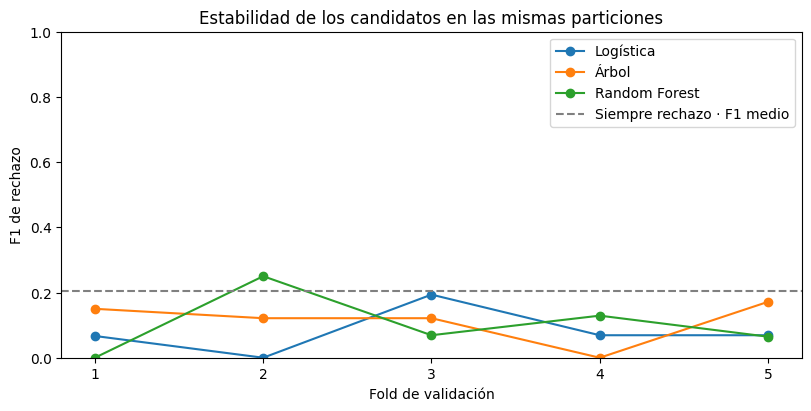

In [31]:
f1_folds = por_fold.loc[por_fold["Modelo"].isin(estimadores)].pivot(
    index="Fold", columns="Modelo", values="F1",
)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for nombre in estimadores:
    ax.plot(f1_folds.index, f1_folds[nombre], marker="o", label=nombre)
ax.axhline(comparacion.loc["Siempre rechazo", "F1"], color="gray", linestyle="--",
           label="Siempre rechazo · F1 medio")
ax.set(xlabel="Fold de validación", ylabel="F1 de rechazo", xticks=f1_folds.index,
       ylim=(0, 1), title="Estabilidad de los candidatos en las mismas particiones")
ax.legend()
plt.show()

Los resultados varían entre folds: todos los modelos tienen alguno con **F1 = 0**. El bosque pasa de **0,704 en entrenamiento a 0,103 en validación**, y el árbol de **0,343 a 0,113**; estas brechas aconsejan revisar su generalización. La logística presenta F1 bajo también al entrenar (**0,098**): no todos los resultados débiles se explican por sobreajuste.

### Lectura de los errores

Sumamos las decisiones de validación: cada registro fue predicho por un ajuste que no lo utilizó para entrenar. Las filas de cada matriz son decisiones históricas y las columnas, predicciones. Un falso rechazo es una aprobación registrada clasificada como rechazo; no acredita una pérdida económica ni un impago.

La matriz agregada ayuda a interpretar los errores. El F1 calculado sobre ella puede diferir del promedio entre folds que decide la comparación.

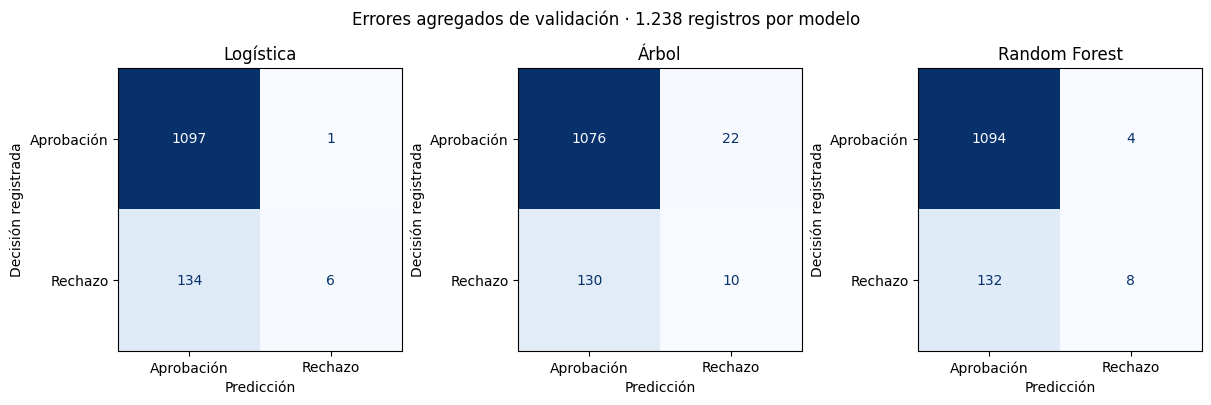

In [32]:
recuentos_errores = pd.DataFrame({
    nombre: confusion_matrix(
        grupo["Real"], grupo["Prediccion"], labels=[0, 1],
    ).ravel()
    for nombre, grupo in predicciones_cv.groupby("Modelo", sort=False)
}, index=["TN", "FP", "FN", "TP"]).T.rename_axis("Modelo")
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, nombre in zip(axes, estimadores):
    matriz = recuentos_errores.loc[nombre].to_numpy().reshape(2, 2)
    ConfusionMatrixDisplay(matriz, display_labels=["Aprobación", "Rechazo"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set(title=nombre, xlabel="Predicción", ylabel="Decisión registrada")
fig.suptitle("Errores agregados de validación · 1.238 registros por modelo")
plt.show()

De los **140 rechazos registrados**, logística detecta **6**, árbol **10** y bosque **8**. A la vez, generan **1, 22 y 4 falsos rechazos**, respectivamente. El problema común es la baja detección con la regla inicial, aunque la accuracy ronde el 88–89 %.

La precisión agregada de estas matrices puede diferir de la media por fold de la tabla anterior; no son cálculos intercambiables. Ninguna de estas cifras mide impagos reales.

### Elección provisional y siguientes mejoras

Aplicamos la tolerancia acordada: entre modelos a no más de **0,01 de F1** del mejor, preferimos logística, árbol y bosque, en ese orden. Las referencias contextualizan el resultado, pero no compiten como familias de modelos. También se comprueba si el candidato supera su mejor F1.

Se selecciona una configuración para continuar investigando, no un modelo final ni el fold que obtuvo mejor resultado.

In [33]:
familias = {"Logística": "regresión logística", "Árbol": "árbol de decisión", "Random Forest": "Random Forest"}
prioridad = {familia: i for i, familia in enumerate(configuracion["prioridad_familias_en_tolerancia"])}
modelos_comparados = comparacion.loc[list(estimadores)]
mejor_f1 = modelos_comparados["F1"].max()
en_tolerancia = modelos_comparados.loc[
    modelos_comparados["F1"].ge(mejor_f1 - configuracion["tolerancia_simplicidad_f1"])
].copy()
en_tolerancia["Prioridad"] = [prioridad[familias[nombre]] for nombre in en_tolerancia.index]
nombre_provisional = en_tolerancia.sort_values(
    ["Prioridad", "F1_std", "F1"], ascending=[True, True, False],
).index[0]
candidato_provisional = clone(candidatos[nombre_provisional])
mejor_referencia = comparacion.loc[["Mayoritaria", "Siempre rechazo"], "F1"].max()
print(f"Candidato provisional: {nombre_provisional}")
print(f"F1 medio: {comparacion.loc[nombre_provisional, 'F1']:.3f}; "
      f"mejor referencia: {mejor_referencia:.3f}")
print("Configuración conservada sin reajuste final; test reservado.")

Candidato provisional: Árbol
F1 medio: 0.113; mejor referencia: 0.203
Configuración conservada sin reajuste final; test reservado.


El **árbol** queda como referencia provisional entre los modelos por su F1 medio, pero **ninguno supera la referencia de siempre rechazo**. No se considera un modelo suficiente para cerrar el proyecto. La diferencia de F1 entre árbol y bosque es **0,01027**, justo fuera de la tolerancia: aplicar esa regla no demuestra superioridad estadística.

La siguiente mejora debe atender a la baja detección: contrastar ponderación o ajuste de umbral en desarrollo, sin confundirlos con mejoras del ranking. El bosque mantiene interés por su ROC-AUC, con una brecha de entrenamiento que también debe vigilarse. El P99 y la exclusión de `CHILDREN` siguen pendientes de contraste por separado.

In [34]:
por_fold.to_csv(REPORTS / "modelos_iniciales_por_fold.csv", index=False)
comparacion.to_csv(REPORTS / "comparacion_inicial.csv")
recuentos_errores.to_csv(REPORTS / "errores_validacion_inicial.csv")
# Archivo local con identificadores, excluido de Git.
predicciones_cv.to_csv(REPORTS / "predicciones_cv_inicial.csv", index=False)
registro_inicial = {
    "evaluacion": "../evaluacion/configuracion.json",
    "muestra": "desarrollo", "umbral": UMBRAL,
    "preparacion": "sección 3; sin recorte ni selección familiar; escalado solo para logística",
    "parametros": {
        nombre: (plantilla.named_steps["modelo"] if isinstance(plantilla, Pipeline) else plantilla).get_params(deep=False)
        for nombre, plantilla in candidatos.items()
    },
    "candidato_provisional": nombre_provisional,
    "reajuste_final": False, "test_evaluado": False,
}
(REPORTS / "configuracion_modelos_iniciales.json").write_text(
    json.dumps(registro_inicial, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
print("Comparación, configuración y errores guardados; predicciones individuales solo en local.")

Comparación, configuración y errores guardados; predicciones individuales solo en local.


La comparación queda registrada con sus configuraciones y resultados por fold. Las predicciones individuales se conservan localmente; los [informes](../reports/README.md) publican únicamente resultados agregados.

La siguiente sección contrastará mejoras concretas en desarrollo. Todavía no se aplica el P99, no se elimina `CHILDREN`, no se ajustan pesos o umbrales y no se evalúa test.

## 5. Mejoras seleccionadas

Pendiente de desarrollo: abordar la baja detección mediante comparaciones acotadas de ponderación o umbral, preservando las particiones y la evaluación interna. Contrastar también, por separado frente a una referencia común, el P99 del ingreso y la exclusión de `CHILDREN`. No se ha implementado ninguna de estas mejoras ni se ha evaluado test.